In [16]:
import pandas as pd
path = "https://raw.githubusercontent.com/ulka29/paper/7aad80ab3fe4ad5ffeabffb7c30bcb70edb218bd/01_data/processed/df_cleaned.csv"# import Check dataset
df= pd.read_csv(path)
df.head()

,tweet_text,cyberbullying_type,clean_tweet,lemmatized_tweet,sentiment_scores,negative,positive,neutral,compound
0,"in other words #katandandre, your food was cra...",not_cyberbullying,words katandandre food crapilicious mkr,word katandandre food crapilicious mkr,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.000,0.000,1.000,0.0000
1,why is #aussietv so white? #mkr #theblock #ima...,not_cyberbullying,aussietv white mkr theblock imacelebrityau tod...,aussietv white mkr theblock imacelebrityau tod...,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.000,0.000,1.000,0.0000
2,@xochitlsuckkks a classy whore? or more red ve...,not_cyberbullying,classy whore red velvet cupcakes,classy whore red velvet cupcake,"{'neg': 0.32, 'neu': 0.481, 'pos': 0.199, 'com...",0.320,0.199,0.481,-0.4137
3,"@jason_gio meh. :p thanks for the heads up, b...",not_cyberbullying,meh p thanks heads concerned another angry dud...,meh p thanks head concerned another angry dude...,"{'neg': 0.243, 'neu': 0.607, 'pos': 0.15, 'com...",0.243,0.150,0.607,-0.4854
4,@rudhoeenglish this is an isis account pretend...,not_cyberbullying,isis account pretending kurdish account like i...,isi account pretending kurdish account like is...,"{'neg': 0.129, 'neu': 0.691, 'pos': 0.18, 'com...",0.129,0.180,0.691,0.0258


In [17]:
# Select relevant features for SA + ML
df_ml = df[
    [
        'lemmatized_tweet',
        'negative',
        'positive',
        'neutral',
        'compound',
        'cyberbullying_type'
    ]
].copy()

# Check shape
print("\n:-------------Shape::-------------", df_ml.shape)

# Check column names
print("\n:-------------Columns::-------------")
print(df_ml.columns.tolist())

# Check missing values
print("\n----------------Missing values:-------------")
print(df_ml.isnull().sum())

# Display first 5 rows
df_ml.head()


:-------------Shape::------------- (42645, 6)

:-------------Columns::-------------
['lemmatized_tweet', 'negative', 'positive', 'neutral', 'compound', 'cyberbullying_type']

----------------Missing values:-------------
lemmatized_tweet      30
negative               0
positive               0
neutral                0
compound               0
cyberbullying_type     0
dtype: int64


,lemmatized_tweet,negative,positive,neutral,compound,cyberbullying_type
0,word katandandre food crapilicious mkr,0.000,0.000,1.000,0.0000,not_cyberbullying
1,aussietv white mkr theblock imacelebrityau tod...,0.000,0.000,1.000,0.0000,not_cyberbullying
2,classy whore red velvet cupcake,0.320,0.199,0.481,-0.4137,not_cyberbullying
3,meh p thanks head concerned another angry dude...,0.243,0.150,0.607,-0.4854,not_cyberbullying
4,isi account pretending kurdish account like is...,0.129,0.180,0.691,0.0258,not_cyberbullying


In [18]:
df = df[df["cyberbullying_type"] != "not_cyberbullying"].reset_index(drop=True)

In [19]:
# ============================================================
# CELL 1: DATA PREPARATION
# WORD TF-IDF + SENTIMENT ANALYSIS
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE
from scipy.sparse import hstack
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. TEXT, SENTIMENT FEATURES AND TARGET
# ------------------------------------------------------------

X_text = df['lemmatized_tweet'].fillna('')
# Sentiment Analysis features
sentiment_features = [
    'negative',
    'positive',
    'neutral',
    'compound'
]

X_sentiment = df[sentiment_features].fillna(0)

# Target variable
y = df['cyberbullying_type']

# ------------------------------------------------------------
# 2. LABEL ENCODING
# ------------------------------------------------------------

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:")
print(label_encoder.classes_)

# Label mapping
label_mapping = dict(
    enumerate(label_encoder.classes_)
)

print("\nLabel Mapping:")

for number, category in label_mapping.items():
    print(f"{number} → {category}")

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_text_train, X_text_test, X_sent_train, X_sent_test, y_train, y_test = train_test_split(
    X_text,
    X_sentiment,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("\nTrain-Test Split")
print("-------------------------")
print("Training samples:", len(X_text_train))
print("Testing samples :", len(X_text_test))

# ------------------------------------------------------------
# 4. TF-IDF VECTORIZATION
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nTF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# 5. COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_train_combined = hstack([
    X_train_tfidf,
    X_sent_train.values
])

X_test_combined = hstack([
    X_test_tfidf,
    X_sent_test.values
])

print("\nCombined Features")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)

Classes:
['age' 'ethnicity' 'gender' 'other_cyberbullying' 'religion']

Label Mapping:
0 → age
1 → ethnicity
2 → gender
3 → other_cyberbullying
4 → religion

Train-Test Split
-------------------------
Training samples: 25340
Testing samples : 10860

TF-IDF Features
-------------------------
X_train TF-IDF: (25340, 10000)
X_test TF-IDF : (10860, 10000)

Combined Features
-------------------------
X_train: (25340, 10004)
X_test : (10860, 10004)


Training TF-IDF Only + Logistic Regression...
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Best Parameters:
{'C': 10}

Best Cross-Validation Weighted F1:
0.9424

TF-IDF ONLY + NO BALANCING
Accuracy     : 0.9453
Weighted F1  : 0.9457
Macro F1     : 0.9397

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.98      0.98      0.98      2387
          ethnicity       0.99      0.99      0.99      2228
             gender       0.92      0.90      0.91      2247
other_cyberbullying       0.82      0.88      0.85      1609
           religion       0.99      0.96      0.98      2389

           accuracy                           0.95     10860
          macro avg       0.94      0.94      0.94     10860
       weighted avg       0.95      0.95      0.95     10860



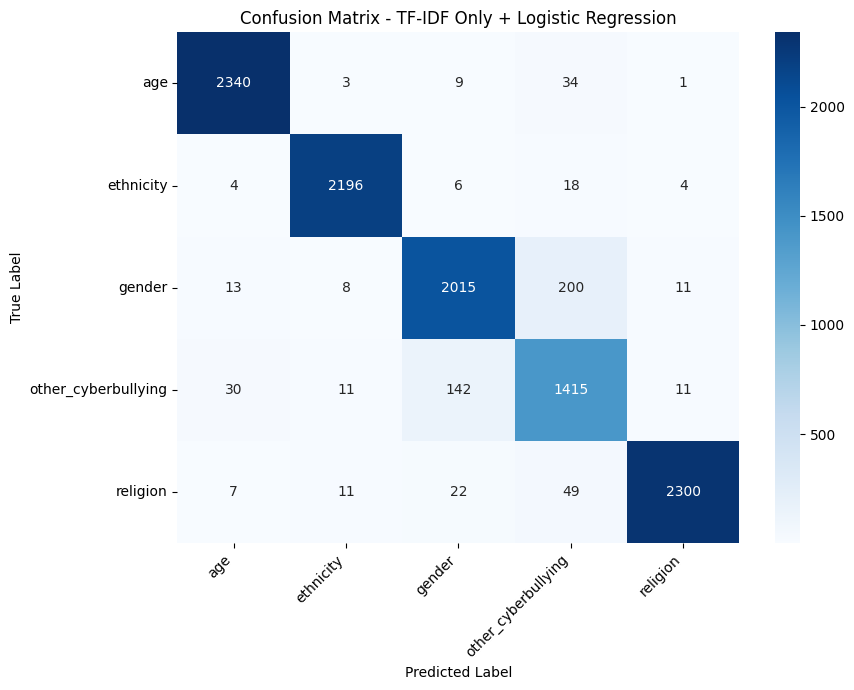

In [20]:
# ============================================================
# WORD TF-IDF ONLY + NO BALANCING + LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION
# ------------------------------------------------------------

lr_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. HYPERPARAMETER GRID
# ------------------------------------------------------------

param_grid = {
    'C': [0.1, 1, 10]
}

# ------------------------------------------------------------
# 3. GRID SEARCH
# ------------------------------------------------------------

grid_tfidf = GridSearchCV(
    estimator=lr_tfidf,
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# ------------------------------------------------------------
# 4. TRAIN ON ORIGINAL TF-IDF DATA
# ------------------------------------------------------------

print("Training TF-IDF Only + Logistic Regression...")

grid_tfidf.fit(
    X_train_tfidf,
    y_train
)

# ------------------------------------------------------------
# 5. BEST MODEL
# ------------------------------------------------------------

best_tfidf = grid_tfidf.best_estimator_

print("\nBest Parameters:")
print(grid_tfidf.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(f"{grid_tfidf.best_score_:.4f}")

# ------------------------------------------------------------
# 6. PREDICTION ON TEST DATA
# ------------------------------------------------------------

y_pred_tfidf = best_tfidf.predict(
    X_test_tfidf
)

# ------------------------------------------------------------
# 7. EVALUATION
# ------------------------------------------------------------

tfidf_accuracy = accuracy_score(
    y_test,
    y_pred_tfidf
)

tfidf_weighted_f1 = f1_score(
    y_test,
    y_pred_tfidf,
    average='weighted'
)

tfidf_macro_f1 = f1_score(
    y_test,
    y_pred_tfidf,
    average='macro'
)

# ------------------------------------------------------------
# 8. FINAL RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("TF-IDF ONLY + NO BALANCING")
print("==============================================")

print(f"Accuracy     : {tfidf_accuracy:.4f}")
print(f"Weighted F1  : {tfidf_weighted_f1:.4f}")
print(f"Macro F1     : {tfidf_macro_f1:.4f}")

# ------------------------------------------------------------
# 9. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_tfidf,
        target_names=label_encoder.classes_
    )
)

# ------------------------------------------------------------
# 10. CONFUSION MATRIX
# ------------------------------------------------------------

cm_tfidf = confusion_matrix(
    y_test,
    y_pred_tfidf
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_tfidf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - TF-IDF Only + Logistic Regression')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# WORD TFIDF + SA + No Balancing + Logistic Regression
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION
# ------------------------------------------------------------

lr_none = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. HYPERPARAMETER GRID
# ------------------------------------------------------------

param_grid = {
    'C': [0.1, 1, 10]
}

# ------------------------------------------------------------
# 3. GRID SEARCH
# ------------------------------------------------------------

grid_none = GridSearchCV(
    estimator=lr_none,
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# ------------------------------------------------------------
# 4. TRAIN ON ORIGINAL DATA
# ------------------------------------------------------------

print("Training SA + No Balancing + Logistic Regression...")

grid_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 5. BEST MODEL
# ------------------------------------------------------------

best_none = grid_none.best_estimator_

print("\nBest Parameters:")
print(grid_none.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(f"{grid_none.best_score_:.4f}")

# ------------------------------------------------------------
# 6. PREDICTION
# ------------------------------------------------------------

y_pred_none = best_none.predict(
    X_test_combined
)

# ------------------------------------------------------------
# 7. EVALUATION
# ------------------------------------------------------------

none_accuracy = accuracy_score(
    y_test,
    y_pred_none
)

none_weighted_f1 = f1_score(
    y_test,
    y_pred_none,
    average='weighted'
)

none_macro_f1 = f1_score(
    y_test,
    y_pred_none,
    average='macro'
)

# ------------------------------------------------------------
# 8. RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("NO BALANCING + LOGISTIC REGRESSION")
print("==============================================")

print(f"Accuracy     : {none_accuracy:.4f}")
print(f"Weighted F1  : {none_weighted_f1:.4f}")
print(f"Macro F1     : {none_macro_f1:.4f}")

# ------------------------------------------------------------
# 9. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(
    classification_report(
        y_test,
        y_pred_none,
        target_names=label_encoder.classes_
    )
)

Training SA + No Balancing + Logistic Regression...
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Best Parameters:
{'C': 10}

Best Cross-Validation Weighted F1:
0.9416

NO BALANCING + LOGISTIC REGRESSION
Accuracy     : 0.9455
Weighted F1  : 0.9459
Macro F1     : 0.9398

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.98      0.98      0.98      2387
          ethnicity       0.98      0.99      0.98      2228
             gender       0.92      0.90      0.91      2247
other_cyberbullying       0.82      0.88      0.85      1609
           religion       0.99      0.96      0.98      2389

           accuracy                           0.95     10860
          macro avg       0.94      0.94      0.94     10860
       weighted avg       0.95      0.95      0.95     10860



In [22]:

# ============================================================
# CELL 1: DATA PREPARATION
# WORD TF-IDF + SENTIMENT ANALYSIS
# Dataset: df_ml
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix
import numpy as np

# ------------------------------------------------------------
# 1. TEXT, SENTIMENT FEATURES AND TARGET
# ------------------------------------------------------------

X_text = df_ml['lemmatized_tweet'].fillna('')

sentiment_features = [
    'negative',
    'positive',
    'neutral',
    'compound'
]

X_sentiment = df_ml[sentiment_features].fillna(0)

y = df_ml['cyberbullying_type']

# ------------------------------------------------------------
# 2. LABEL ENCODING
# ------------------------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes:")
print(label_encoder.classes_)

label_mapping = dict(enumerate(label_encoder.classes_))

print("\nLabel Mapping:")
for number, category in label_mapping.items():
    print(f"{number} -> {category}")

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

(
    X_text_train,
    X_text_test,
    X_sent_train,
    X_sent_test,
    y_train,
    y_test
) = train_test_split(
    X_text,
    X_sentiment,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("\nTrain-Test Split")
print("-------------------------")
print("Training samples:", len(X_text_train))
print("Testing samples :", len(X_text_test))

# ------------------------------------------------------------
# 4. WORD TF-IDF VECTORIZATION
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("\nWord TF-IDF Features")
print("-------------------------")
print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)

# ------------------------------------------------------------
# 5. COMBINE TF-IDF + SENTIMENT FEATURES
# ------------------------------------------------------------

X_sent_train_sparse = csr_matrix(
    X_sent_train.to_numpy(dtype=float)
)

X_sent_test_sparse = csr_matrix(
    X_sent_test.to_numpy(dtype=float)
)

X_train_combined = hstack(
    [X_train_tfidf, X_sent_train_sparse],
    format='csr'
)

X_test_combined = hstack(
    [X_test_tfidf, X_sent_test_sparse],
    format='csr'
)

print("\nCombined Features: Word TF-IDF + Sentiment")
print("-------------------------")
print("X_train:", X_train_combined.shape)
print("X_test :", X_test_combined.shape)

Classes:
['age' 'ethnicity' 'gender' 'not_cyberbullying' 'other_cyberbullying'
 'religion']

Label Mapping:
0 -> age
1 -> ethnicity
2 -> gender
3 -> not_cyberbullying
4 -> other_cyberbullying
5 -> religion

Train-Test Split
-------------------------
Training samples: 29851
Testing samples : 12794

Word TF-IDF Features
-------------------------
X_train TF-IDF: (29851, 10000)
X_test TF-IDF : (12794, 10000)

Combined Features: Word TF-IDF + Sentiment
-------------------------
X_train: (29851, 10004)
X_test : (12794, 10004)


Training Word TF-IDF + No Balancing + Logistic Regression...
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Best Parameters:
{'C': 1}

Best CV Weighted F1:
0.8426

WORD TF-IDF ONLY + NO BALANCING + LR
Accuracy     : 0.8487
Weighted F1  : 0.8497
Macro F1     : 0.8298

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.92      0.85      0.88      2248
  not_cyberbullying       0.60      0.63      0.61      1934
other_cyberbullying       0.59      0.59      0.59      1608
           religion       0.96      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



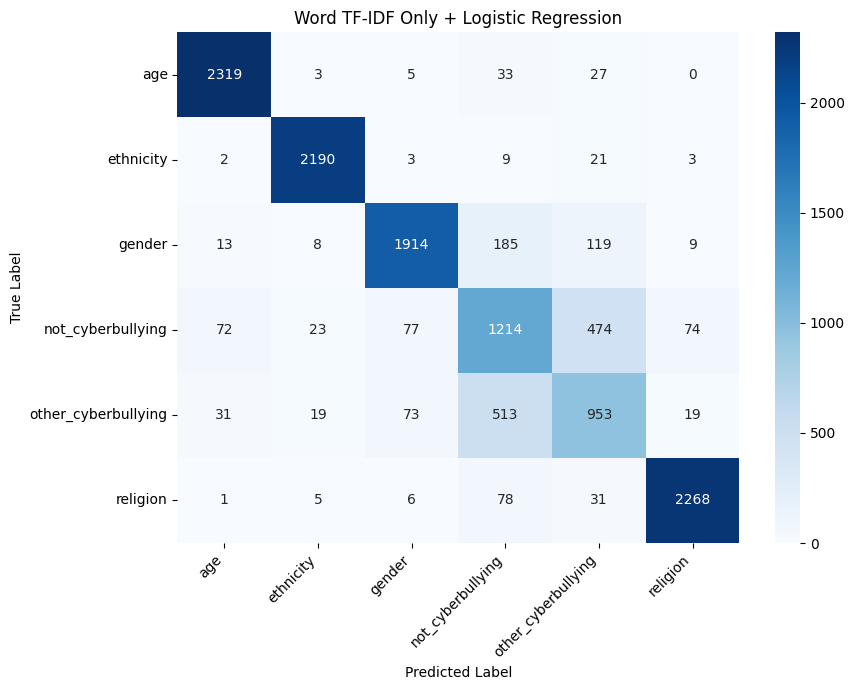

In [23]:

# ============================================================
# CELL 2: WORD TF-IDF ONLY
# NO BALANCING + LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. MODEL
# ------------------------------------------------------------

lr_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. HYPERPARAMETER GRID
# ------------------------------------------------------------

param_grid = {
    'C': [0.1, 1, 10]
}

# ------------------------------------------------------------
# 3. GRID SEARCH
# ------------------------------------------------------------

grid_tfidf = GridSearchCV(
    estimator=lr_tfidf,
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# ------------------------------------------------------------
# 4. TRAIN
# ------------------------------------------------------------

print("Training Word TF-IDF + No Balancing + Logistic Regression...")

grid_tfidf.fit(
    X_train_tfidf,
    y_train
)

# ------------------------------------------------------------
# 5. BEST MODEL
# ------------------------------------------------------------

best_tfidf = grid_tfidf.best_estimator_

print("\nBest Parameters:")
print(grid_tfidf.best_params_)

print("\nBest CV Weighted F1:")
print(f"{grid_tfidf.best_score_:.4f}")

# ------------------------------------------------------------
# 6. TEST PREDICTION
# ------------------------------------------------------------

y_pred_tfidf = best_tfidf.predict(X_test_tfidf)

# ------------------------------------------------------------
# 7. EVALUATION
# ------------------------------------------------------------

tfidf_accuracy = accuracy_score(y_test, y_pred_tfidf)

tfidf_weighted_f1 = f1_score(
    y_test, y_pred_tfidf, average='weighted'
)

tfidf_macro_f1 = f1_score(
    y_test, y_pred_tfidf, average='macro'
)

print("\n==============================================")
print("WORD TF-IDF ONLY + NO BALANCING + LR")
print("==============================================")
print(f"Accuracy     : {tfidf_accuracy:.4f}")
print(f"Weighted F1  : {tfidf_weighted_f1:.4f}")
print(f"Macro F1     : {tfidf_macro_f1:.4f}")

# ------------------------------------------------------------
# 8. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(classification_report(
    y_test,
    y_pred_tfidf,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

cm_tfidf = confusion_matrix(
    y_test,
    y_pred_tfidf,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_tfidf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Word TF-IDF Only + Logistic Regression')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:

# ============================================================
# CELL 3: WORD TF-IDF + SENTIMENT ANALYSIS
# NO BALANCING + LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# ------------------------------------------------------------
# 1. MODEL
# ------------------------------------------------------------

lr_none = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# ------------------------------------------------------------
# 2. HYPERPARAMETER GRID
# ------------------------------------------------------------

param_grid = {
    'C': [0.1, 1, 10]
}

# ------------------------------------------------------------
# 3. GRID SEARCH
# ------------------------------------------------------------

grid_none = GridSearchCV(
    estimator=lr_none,
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# ------------------------------------------------------------
# 4. TRAIN ON ORIGINAL, UNBALANCED DATA
# ------------------------------------------------------------

print("Training Word TF-IDF + Sentiment + No Balancing + LR...")

grid_none.fit(
    X_train_combined,
    y_train
)

# ------------------------------------------------------------
# 5. BEST MODEL
# ------------------------------------------------------------

best_none = grid_none.best_estimator_

print("\nBest Parameters:")
print(grid_none.best_params_)

print("\nBest CV Weighted F1:")
print(f"{grid_none.best_score_:.4f}")

# ------------------------------------------------------------
# 6. TEST PREDICTION
# ------------------------------------------------------------

y_pred_none = best_none.predict(X_test_combined)

# ------------------------------------------------------------
# 7. EVALUATION
# ------------------------------------------------------------

none_accuracy = accuracy_score(y_test, y_pred_none)

none_weighted_f1 = f1_score(
    y_test, y_pred_none, average='weighted'
)

none_macro_f1 = f1_score(
    y_test, y_pred_none, average='macro'
)

print("\n==============================================")
print("WORD TF-IDF + SENTIMENT + NO BALANCING + LR")
print("==============================================")

print(f"Accuracy     : {none_accuracy:.4f}")
print(f"Weighted F1  : {none_weighted_f1:.4f}")
print(f"Macro F1     : {none_macro_f1:.4f}")

# ------------------------------------------------------------
# 8. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report")
print("-------------------------")

print(classification_report(
    y_test,
    y_pred_none,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Training Word TF-IDF + Sentiment + No Balancing + LR...
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Best Parameters:
{'C': 1}

Best CV Weighted F1:
0.8420

WORD TF-IDF + SENTIMENT + NO BALANCING + LR
Accuracy     : 0.8495
Weighted F1  : 0.8504
Macro F1     : 0.8307

Classification Report
-------------------------
                     precision    recall  f1-score   support

                age       0.95      0.97      0.96      2387
          ethnicity       0.97      0.98      0.98      2228
             gender       0.92      0.85      0.88      2248
  not_cyberbullying       0.60      0.63      0.62      1934
other_cyberbullying       0.59      0.59      0.59      1608
           religion       0.95      0.95      0.95      2389

           accuracy                           0.85     12794
          macro avg       0.83      0.83      0.83     12794
       weighted avg       0.85      0.85      0.85     12794



Here we analyzed the difference of the accuracy we achieved without not cyber bully and with not cyberbully included without not cyberbully accuracy was similar to paper [] which dropped column given in paper sosnet [] given but when we did not remove that column we observed some difference in the accuracy